In [1]:
# ==============================================================================
# CELL 1: Setup & Dependencies
# ==============================================================================
import itertools
import random
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix seeds across libraries for experiment reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Formatting configuration for 1080p 16:9 monitor display
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.autolayout": True
})

print("✓ Cell 1 complete: Libraries loaded & graphics initialized for 1080p display.")

✓ Cell 1 complete: Libraries loaded & graphics initialized for 1080p display.


In [2]:
# ==============================================================================
# CELL 2: Constants, Parameter Mappings & Baseline Config (UPDATED)
# ==============================================================================
from typing import Dict, List

# 1. Categorical Personality Level Multipliers
TRAIT_LEVEL_MAP: Dict[str, float] = {
    "High": 0.8,
    "Medium": 0.5,
    "Low": 0.2
}

TRAIT_NAMES: List[str] = [
    "Cognitive_Ability",
    "Conscientiousness",
    "Curiosity",
    "Risk_Tolerance"
]

TRAIT_LEVEL_KEYS: List[str] = ["High", "Medium", "Low"]

# 2. Dynamic Life State Initial Values (Agent Baseline)
INIT_KNOWLEDGE: float = 20.0
INIT_MONEY: float = 300.0        # Buffer calibrated to allow learning curves before debt
INIT_HEALTH: float = 100.0
INIT_NETWORK: float = 20.0

# Fixed expenses deducted every simulation day
LIVING_COST: float = 3.0         # Calibrated daily runway

# ------------------------------------------------------------------------------
# [MODIFICATION A] Insolvency & Bankruptcy Mechanics
# ------------------------------------------------------------------------------
BANKRUPTCY_THRESHOLD: float = -300.0        # Debt cap that triggers bankruptcy reset
BANKRUPTCY_HEALTH_PENALTY: float = 15.0     # Physical health tax on financial failure
BANKRUPTCY_NETWORK_PENALTY_PCT: float = 0.30 # Loss of social capital on bankruptcy (30%)

# 3. Baseline Environment Factors (Societal Norms = 1.0)
BASE_EDUCATION_QUALITY: float = 1.0
BASE_ECONOMIC_GROWTH: float = 1.0
BASE_HEALTHCARE_QUALITY: float = 1.0
BASE_SOCIAL_MOBILITY: float = 1.0

# 4. Event & Simulation Runtime Parameters
SIMULATION_DAYS: int = 18250
SHOCK_MIN_DURATION: int = 30         # Optimized shock duration for clearer delta tracking
SHOCK_MAX_DURATION: int = 70
SHOCK_PROBABILITY: float = 0.003     # ~1 macro shock per year

print("✓ Cell 2 complete: Updated with Insolvency constants (Mod A) and calibrated baselines.")

✓ Cell 2 complete: Updated with Insolvency constants (Mod A) and calibrated baselines.


In [3]:
# ==============================================================================
# CELL 3: Environment Class & Temporary Macro Event (Shock) Engine
# ==============================================================================

@dataclass
class ShockEvent:
    name: str
    affected_attribute: str
    multiplier: float
    duration: int
    remaining_days: int


class Environment:
    """Manages global societal conditions and temporary macroeconomic/social shocks."""
    
    def __init__(self):
        self.reset()

    def reset(self):
        # Baseline environmental settings
        self.base_education_quality = BASE_EDUCATION_QUALITY
        self.base_economic_growth = BASE_ECONOMIC_GROWTH
        self.base_healthcare_quality = BASE_HEALTHCARE_QUALITY
        self.base_social_mobility = BASE_SOCIAL_MOBILITY

        # Current effective environmental settings
        self.education_quality = BASE_EDUCATION_QUALITY
        self.economic_growth = BASE_ECONOMIC_GROWTH
        self.healthcare_quality = BASE_HEALTHCARE_QUALITY
        self.social_mobility = BASE_SOCIAL_MOBILITY

        # Active event tracker
        self.active_shock: Optional[ShockEvent] = None

    def step(self):
        """Advances the environment by 1 day, handling active shock countdowns or new triggers."""
        # 1. Process existing active shock
        if self.active_shock:
            self.active_shock.remaining_days -= 1
            if self.active_shock.remaining_days <= 0:
                self._reset_to_baseline()
                self.active_shock = None

        # 2. Roll for new shock if environment is currently stable
        elif random.random() < SHOCK_PROBABILITY:
            self._trigger_random_shock()

    def _reset_to_baseline(self):
        """Restores all environmental variables back to baseline levels."""
        self.education_quality = self.base_education_quality
        self.economic_growth = self.base_economic_growth
        self.healthcare_quality = self.base_healthcare_quality
        self.social_mobility = self.base_social_mobility

    def _trigger_random_shock(self):
        """Generates a temporary macro event lasting between 50 and 100 days."""
        duration = random.randint(SHOCK_MIN_DURATION, SHOCK_MAX_DURATION)
        
        # Catalog of macro shocks with direct multipliers on global variables
        possible_shocks = [
            ("Economic Recession", "economic_growth", 0.60),      # -40% Economic Growth
            ("Economic Boom", "economic_growth", 1.40),           # +40% Economic Growth
            ("Healthcare Crisis", "healthcare_quality", 0.60),    # -40% Healthcare Quality
            ("Education Reform", "education_quality", 1.30),      # +30% Education Quality
            ("Social Stagnation", "social_mobility", 0.50),       # -50% Social Mobility
        ]
        
        name, attr, multiplier = random.choice(possible_shocks)
        
        # Apply temporary modifier to current state
        base_value = getattr(self, f"base_{attr}")
        setattr(self, attr, base_value * multiplier)
        
        self.active_shock = ShockEvent(
            name=name,
            affected_attribute=attr,
            multiplier=multiplier,
            duration=duration,
            remaining_days=duration
        )

    def get_state(self) -> Dict[str, float]:
        """Returns snapshot of current global environmental values."""
        return {
            "education_quality": self.education_quality,
            "economic_growth": self.economic_growth,
            "healthcare_quality": self.healthcare_quality,
            "social_mobility": self.social_mobility,
            "active_shock_name": self.active_shock.name if self.active_shock else "None"
        }

print("✓ Cell 3 complete: Environment class with 50-100 day macro shock engine initialized.")

✓ Cell 3 complete: Environment class with 50-100 day macro shock engine initialized.


In [4]:
# ==============================================================================
# CELL 4: Personality Archetype Generator (81 Unique Combinations)
# ==============================================================================

@dataclass
class Archetype:
    id: int
    code: str                     # Short code e.g., "H-H-M-L"
    traits: Dict[str, str]        # Categorical: {"Cognitive_Ability": "High", ...}
    weights: Dict[str, float]     # Numerical:   {"Cognitive_Ability": 0.8, ...}


def generate_all_archetypes() -> Dict[int, Archetype]:
    """Generates all 3^4 = 81 unique combinations of the 4 personality traits."""
    archetypes = {}
    
    # Generate Cartesian product of [High, Medium, Low] across 4 traits
    combinations = list(itertools.product(TRAIT_LEVEL_KEYS, repeat=4))
    
    for idx, combo in enumerate(combinations, start=1):
        traits = dict(zip(TRAIT_NAMES, combo))
        weights = {trait: TRAIT_LEVEL_MAP[level] for trait, level in traits.items()}
        
        # Compact 4-letter code identifier (e.g., "H-M-L-H")
        code = "-".join([level[0] for level in combo])
        
        archetypes[idx] = Archetype(
            id=idx,
            code=code,
            traits=traits,
            weights=weights
        )
        
    return archetypes


# Instantiate global archetype registry
ARCHETYPES = generate_all_archetypes()

# Convert to Pandas DataFrame for clear review on your 1080p display
archetype_preview_data = []
for a in ARCHETYPES.values():
    row = {"ID": a.id, "Code": a.code}
    row.update(a.traits)
    archetype_preview_data.append(row)

df_archetypes = pd.DataFrame(archetype_preview_data)

print(f"✓ Cell 4 complete: Successfully generated all {len(ARCHETYPES)} personality archetypes.")
print("\nFirst 5 Archetypes Preview:")
display(df_archetypes.head(10))

✓ Cell 4 complete: Successfully generated all 81 personality archetypes.

First 5 Archetypes Preview:


,ID,Code,Cognitive_Ability,Conscientiousness,Curiosity,Risk_Tolerance
0,1,H-H-H-H,High,High,High,High
1,2,H-H-H-M,High,High,High,Medium
2,3,H-H-H-L,High,High,High,Low
3,4,H-H-M-H,High,High,Medium,High
4,5,H-H-M-M,High,High,Medium,Medium
5,6,H-H-M-L,High,High,Medium,Low
6,7,H-H-L-H,High,High,Low,High
7,8,H-H-L-M,High,High,Low,Medium
8,9,H-H-L-L,High,High,Low,Low
9,10,H-M-H-H,High,Medium,High,High


In [5]:
# ==============================================================================
# CELL 5: Agent Class & Dynamic Life State Tracking (UPDATED)
# ==============================================================================
from typing import Dict, Optional

class Agent:
    """Represents an individual agent in the simulation holding dynamic life capitals."""

    def __init__(self, agent_id: int, archetype: Archetype):
        self.agent_id = agent_id
        self.archetype = archetype

        # Dynamic Life Capitals (Initialized from Cell 2 defaults)
        self.knowledge: float = INIT_KNOWLEDGE
        self.money: float = INIT_MONEY
        self.health: float = INIT_HEALTH
        self.network: float = INIT_NETWORK

        # Action history & state tracking
        self.last_action: Optional[str] = None
        self.days_in_debt: int = 0
        self.bankruptcies_count: int = 0  # Tracks resilience vs structural failure

    def apply_daily_upkeep(self):
        """Applies daily upkeep, living expenses, base health decay, and insolvency logic."""
        # 1. Deduct daily living cost
        self.money -= LIVING_COST

        # 2. Track debt duration
        if self.money < 0:
            self.days_in_debt += 1

        # 3. Passive daily health decay (base wear-and-tear)
        self.health -= 0.1

        # 4. [MODIFICATION A] Check and process bankruptcy if debt threshold is hit
        self.check_insolvency()

        # 5. Ensure non-financial states stay within physical bounds
        self.clamp_states()

    def check_insolvency(self):
        """Triggers a bankruptcy reset if agent debt hits BANKRUPTCY_THRESHOLD."""
        if self.money <= BANKRUPTCY_THRESHOLD:
            # Reset financial debt back to zero floor
            self.money = 0.0

            # Apply structural health and social capital penalties
            self.health -= BANKRUPTCY_HEALTH_PENALTY
            self.network *= (1.0 - BANKRUPTCY_NETWORK_PENALTY_PCT)

            # Record bankruptcy event
            self.bankruptcies_count += 1

    def clamp_states(self):
        """Ensures non-financial capitals stay within physical bounds."""
        self.health = max(0.0, min(100.0, self.health))
        self.knowledge = max(0.0, self.knowledge)
        self.network = max(0.0, self.network)
        # Note: Money is allowed to go negative between 0.0 and BANKRUPTCY_THRESHOLD

    def get_trait_weight(self, trait_name: str) -> float:
        """Helper to fetch numerical personality weight (0.2, 0.5, or 0.8)."""
        return self.archetype.weights[trait_name]

    def get_state(self) -> Dict[str, float]:
        """Returns a snapshot of current dynamic capitals and health indicators."""
        return {
            "knowledge": self.knowledge,
            "money": self.money,
            "health": self.health,
            "network": self.network,
            "in_debt": self.money < 0,
            "bankruptcies": self.bankruptcies_count
        }


print("✓ Cell 5 complete: Insolvency reset mechanism and state snapshot tracking integrated.")

✓ Cell 5 complete: Insolvency reset mechanism and state snapshot tracking integrated.


In [6]:
# ==============================================================================
# CELL 6: Rule-Based Decision Engine
# ==============================================================================

AVAILABLE_ACTIONS = [
    "Work",
    "Study",
    "Exercise",
    "Network",
    "Rest",
    "Start_Business"
]


def select_daily_action(agent: Agent) -> str:
    """Evaluates utility scores for each candidate action and returns the chosen action.
    
    Decision Rules:
    - Low Health (< 30): Health survival overrides normal preferences (forces Rest or Exercise).
    - Financial Debt (Money < 0): Increases urgency to Work proportional to debt depth.
    - Conscientiousness: Drives inclination to Work.
    - Curiosity: Drives inclination to Study and Network.
    - Risk Tolerance: Enables entrepreneurial attempts when prerequisite capitals are met.
    """
    scores: Dict[str, float] = {}

    # Fetch agent trait weights (0.2 = Low, 0.5 = Medium, 0.8 = High)
    cog = agent.get_trait_weight("Cognitive_Ability")
    con = agent.get_trait_weight("Conscientiousness")
    cur = agent.get_trait_weight("Curiosity")
    risk = agent.get_trait_weight("Risk_Tolerance")

    # 1. Critical Health Override
    if agent.health < 25.0:
        # Emergency recovery mode
        return "Rest" if agent.health < 15.0 else "Exercise"

    # 2. Evaluate 'Work' Preference
    # Baseline driven by Conscientiousness + boosted heavily if in debt
    debt_multiplier = abs(agent.money) * 0.15 if agent.money < 0 else 0.0
    scores["Work"] = (con * 10.0) + debt_multiplier

    # 3. Evaluate 'Study' Preference
    # Driven by Curiosity and Cognitive Ability
    scores["Study"] = (cur * 8.0) + (cog * 4.0)

    # 4. Evaluate 'Exercise' Preference
    # Driven by health deficit (desire to stay healthy) modified by Conscientiousness
    health_deficit = (100.0 - agent.health) / 100.0
    scores["Exercise"] = (health_deficit * 6.0) + (con * 2.0)

    # 5. Evaluate 'Network' Preference
    # Driven by Curiosity and current social base
    network_base = min(agent.network / 50.0, 2.0)
    scores["Network"] = (cur * 6.0) + (network_base * 2.0)

    # 6. Evaluate 'Rest' Preference
    # Rest restores stamina when health drops below 70
    fatigue_factor = max(0.0, (70.0 - agent.health) / 10.0)
    scores["Rest"] = fatigue_factor * 1.5

    # 7. Evaluate 'Start_Business' (Entrepreneurship)
    # Gated by Risk Tolerance and minimum capital thresholds (Knowledge >= 20, Money >= 30)
    if agent.money >= 30.0 and agent.knowledge >= 20.0:
        scores["Start_Business"] = (risk * 12.0) + (cog * 3.0)
    else:
        scores["Start_Business"] = 0.0  # Cannot afford or lack requisite knowledge

    # Pick the action with the highest calculated utility score
    chosen_action = max(scores, key=scores.get)
    return chosen_action


print("✓ Cell 6 complete: Rule-based decision engine with health & debt overrides ready.")

✓ Cell 6 complete: Rule-based decision engine with health & debt overrides ready.


In [7]:
# ==============================================================================
# CELL 7: Action Efficiency & Feedback Loop Engine (UPDATED)
# ==============================================================================
import random

def execute_action_outcome(agent: Agent, action: str, env: Environment):
    """Calculates state changes based on chosen action, personality, and environment."""
    
    # Retrieve trait weights (0.2 = Low, 0.5 = Medium, 0.8 = High)
    cog = agent.get_trait_weight("Cognitive_Ability")
    con = agent.get_trait_weight("Conscientiousness")
    cur = agent.get_trait_weight("Curiosity")
    risk = agent.get_trait_weight("Risk_Tolerance")

    if action == "Work":
        # Income scale: Conscientiousness drives base efficiency, Knowledge provides leverage,
        # Economic growth boosts yield, Health scales physical effort capacity.
        base_income = 12.0 * con
        knowledge_leverage = 1.0 + (agent.knowledge / 40.0)
        health_factor = max(0.2, agent.health / 100.0)
        
        income = base_income * knowledge_leverage * health_factor * env.economic_growth
        
        agent.money += income
        agent.health -= 0.35  # Physical wear from labor

    elif action == "Study":
        # Knowledge acquisition: Cognitive ability + Curiosity drive learning rate,
        # boosted by societal Education Quality. Requires tuition/materials cost.
        base_learn = 2.5 * cog * (1.0 + cur)
        health_factor = max(0.5, agent.health / 100.0)
        
        knowledge_gain = base_learn * env.education_quality * health_factor
        
        agent.knowledge += knowledge_gain
        agent.money -= 2.0   # Cost of books, courses, or tuition

    elif action == "Exercise":
        # Health recovery: Boosted by Healthcare Quality and Conscientiousness consistency.
        health_gain = 3.5 * env.healthcare_quality * (1.0 + 0.25 * con)
        agent.health += health_gain

    elif action == "Network":
        # Social capital expansion: Driven by Curiosity and existing Knowledge base,
        # amplified by Social Mobility. Costs social spending money.
        knowledge_factor = 1.0 + (agent.knowledge / 50.0)
        network_gain = 2.0 * cur * knowledge_factor * env.social_mobility
        
        agent.network += network_gain
        agent.money -= 3.0   # Spending on events, dining, and meetings

    elif action == "Rest":
        # Passive recovery from fatigue
        agent.health += 5.0 * env.healthcare_quality

    elif action == "Start_Business":
        # Entrepreneurship: High risk/reward attempt.
        # Probability of success depends on Knowledge, Network, Risk Tolerance, and Economic Growth.
        success_prob = min(
            0.85, 
            (0.15 + (0.35 * risk) + (agent.knowledge / 150.0) + (agent.network / 200.0)) * env.economic_growth
        )
        
        if random.random() < success_prob:
            # Successful venture: Huge payout in Money & Network
            agent.money += 45.0 * env.economic_growth
            agent.network += 12.0
        else:
            # Failed venture: Financial loss & minor social hit
            agent.money -= 25.0
            agent.network = max(0.0, agent.network - 3.0)
            
        agent.health -= 1.0  # High stress toll

    # [MODIFICATION A INTEGRATION] Check if action outcome caused insolvency
    agent.check_insolvency()

    # Finalize state limits (ensure health <= 100, non-negative capitals)
    agent.clamp_states()


print("✓ Cell 7 complete: Action outcomes updated with instant insolvency checks.")

✓ Cell 7 complete: Action outcomes updated with instant insolvency checks.


In [8]:
# ==============================================================================
# CELL 8: Batch Simulation Runner
# ==============================================================================

def print_annual_report(year: int, day: int, env: Environment, population: List[Agent]):
    """Prints a formatted annual status dashboard on your 1080p display."""
    
    # Calculate population metrics
    avg_money = np.mean([a.money for a in population])
    avg_knowledge = np.mean([a.knowledge for a in population])
    avg_health = np.mean([a.health for a in population])
    avg_network = np.mean([a.network for a in population])
    
    debt_count = sum(1 for a in population if a.money < 0)
    debt_rate = (debt_count / len(population)) * 100.0
    
    # Identify top and bottom performing archetypes by composite net capitals
    archetype_totals = {}
    for agent in population:
        code = agent.archetype.code
        score = agent.money + agent.knowledge * 2.0 + agent.network * 1.5
        archetype_totals.setdefault(code, []).append(score)
        
    avg_scores = {code: np.mean(scores) for code, scores in archetype_totals.items()}
    top_code = max(avg_scores, key=avg_scores.get)
    bot_code = min(avg_scores, key=avg_scores.get)
    
    shock_status = env.active_shock.name if env.active_shock else "Stable (None)"

    # Format annual printout
    print("=" * 105)
    print(f" 📊 END OF YEAR {year:2d} | Day {day:4d} / {SIMULATION_DAYS} | Macro Environment Status: [{shock_status}]")
    print("-" * 105)
    print(f"  Population Averages  │ Money: ${avg_money:8.2f} │ Knowledge: {avg_knowledge:6.1f} │ "
          f"Health: {avg_health:5.1f} │ Network: {avg_network:6.1f} │ In Debt: {debt_rate:4.1f}%")
    print(f"  Archetype Highlights │ Leading Traits: [{top_code}] (Score: {avg_scores[top_code]:7.1f}) │ "
          f"Lagging Traits: [{bot_code}] (Score: {avg_scores[bot_code]:7.1f})")
    print("=" * 105 + "\n")


def run_simulation(agents_per_archetype: int = 5) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Executes the full multi-year simulation across all 81 personality archetypes."""
    
    env = Environment()
    
    # Instantiate population (81 archetypes * agents_per_archetype)
    population: List[Agent] = []
    agent_id_counter = 1
    for archetype in ARCHETYPES.values():
        for _ in range(agents_per_archetype):
            population.append(Agent(agent_id=agent_id_counter, archetype=archetype))
            agent_id_counter += 1

    print(f"🚀 Starting Simulation: {len(population)} agents across {len(ARCHETYPES)} personality archetypes.")
    print(f"   Duration: {SIMULATION_DAYS} days (~{SIMULATION_DAYS / 365} Years)\n")

    history_logs = []
    
    # Sampling interval for video animation (Every 5 days = 730 smooth frames)
    RECORD_INTERVAL = 5

    # Daily Simulation Loop
    for day in range(1, SIMULATION_DAYS + 1):
        # 1. Advance environmental shocks
        env.step()
        
        # 2. Process each agent
        for agent in population:
            chosen_action = select_daily_action(agent)
            execute_action_outcome(agent, chosen_action, env)
            agent.apply_daily_upkeep()

        # 3. Log historical snapshot for Bar Chart Race video (Cell 8.5)
        if day % RECORD_INTERVAL == 0 or day == 1 or day == SIMULATION_DAYS:
            macro_info = env.get_state()
            for agent in population:
                history_logs.append({
                    "Day": day,
                    "Year": (day - 1) // 365 + 1,
                    "Agent_ID": agent.agent_id,
                    "Archetype_ID": agent.archetype.id,
                    "Code": agent.archetype.code,
                    "Money": agent.money,
                    "Knowledge": agent.knowledge,
                    "Health": agent.health,
                    "Network": agent.network,
                    "Composite_Score": agent.money * 1.0 + agent.knowledge * 2.5 + agent.health * 1.5 + agent.network * 2.0,
                    "Active_Shock": macro_info["active_shock_name"]
                })

        # 4. Print Annual Report every 365 days
        if day % 365 == 0:
            year = day // 365
            print_annual_report(year, day, env, population)
            
    # Compile historical trajectory DataFrame
    df_history = pd.DataFrame(history_logs)

    # Compile Final Snapshot DataFrame
    final_data = []
    for a in population:
        row = {
            "Agent_ID": a.agent_id,
            "Archetype_ID": a.archetype.id,
            "Code": a.archetype.code,
            "Cognitive_Ability": a.archetype.traits["Cognitive_Ability"],
            "Conscientiousness": a.archetype.traits["Conscientiousness"],
            "Curiosity": a.archetype.traits["Curiosity"],
            "Risk_Tolerance": a.archetype.traits["Risk_Tolerance"],
            "Final_Money": a.money,
            "Final_Knowledge": a.knowledge,
            "Final_Health": a.health,
            "Final_Network": a.network,
            "Days_In_Debt": a.days_in_debt
        }
        final_data.append(row)

    df_results = pd.DataFrame(final_data)
    return df_results, df_history, population


# Execute the run (20 agents per archetype = 1620 total agents)
AGENTS_PER_ARCHETYPE = 20
df_results, df_history, population = run_simulation(agents_per_archetype=AGENTS_PER_ARCHETYPE)

print("✓ Cell 8 complete: Simulation run finished successfully and datasets compiled.")

🚀 Starting Simulation: 1620 agents across 81 personality archetypes.
   Duration: 18250 days (~50.0 Years)

 📊 END OF YEAR  1 | Day  365 / 18250 | Macro Environment Status: [Stable (None)]
---------------------------------------------------------------------------------------------------------
  Population Averages  │ Money: $ 4589.05 │ Knowledge:  166.2 │ Health:  30.9 │ Network: 1422.9 │ In Debt: 23.5%
  Archetype Highlights │ Leading Traits: [M-H-H-H] (Score: 13935.6) │ Lagging Traits: [L-L-L-L] (Score:   -99.2)

 📊 END OF YEAR  2 | Day  730 / 18250 | Macro Environment Status: [Stable (None)]
---------------------------------------------------------------------------------------------------------
  Population Averages  │ Money: $ 8798.55 │ Knowledge:  253.8 │ Health:  27.3 │ Network: 2749.2 │ In Debt: 19.8%
  Archetype Highlights │ Leading Traits: [L-M-L-M] (Score: 27463.5) │ Lagging Traits: [L-L-L-L] (Score:   -14.0)

 📊 END OF YEAR  3 | Day 1095 / 18250 | Macro Environment Status:

In [9]:
# ==============================================================================
# CELL 8.5: Macro-Enhanced Bar Chart Race Video Generator & Daily History Logger
# ==============================================================================

# ------------------------------------------------------------------------------
# 0. User Configuration Controls
# ------------------------------------------------------------------------------
RENDER_VIDEO = False  # Set to False to skip video rendering and save runtime

import os
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# 1. Define output directory matching user specification
output_folder = (
    f"./video/APA_{AGENTS_PER_ARCHETYPE}"
    f"_edu_{BASE_EDUCATION_QUALITY}"
    f"_eco_{BASE_ECONOMIC_GROWTH}"
    f"_heal_{BASE_HEALTHCARE_QUALITY}"
    f"_mob_{BASE_SOCIAL_MOBILITY}"
)
os.makedirs(output_folder, exist_ok=True)
print(f"📁 Output destination set to: {output_folder}")

# 2. ALWAYS Aggregate daily history by Archetype Code & Save CSV Log
df_daily_archetype = df_history.groupby(["Day", "Year", "Code", "Active_Shock"]).agg(
    Mean_Composite=("Composite_Score", "mean"),
    Mean_Money=("Money", "mean"),
    In_Debt_Pct=("Money", lambda x: (x < 0).mean() * 100)
).reset_index()

csv_daily_path = os.path.join(output_folder, "daily_archetype_history.csv")
df_daily_archetype.to_csv(csv_daily_path, index=False)
print(f"💾 Daily aggregated history log saved to: {csv_daily_path}")

# 3. Conditional Video Rendering Block
if RENDER_VIDEO:
    print("\n🎬 RENDER_VIDEO is enabled. Initializing MP4 video generation...")

    # Dynamically configure Matplotlib to use imageio-ffmpeg binary
    try:
        import imageio_ffmpeg
        ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
        plt.rcParams["animation.ffmpeg_path"] = ffmpeg_exe
        print(f"🎥 Connected imageio-ffmpeg binary: {ffmpeg_exe}")
    except ImportError:
        print("⚠️ imageio-ffmpeg not found. Please ensure 'pip install imageio-ffmpeg' is run in your environment.")

    video_path = os.path.join(output_folder, "bar_chart_race.mp4")

    # Assign Color-Coding based on Dominant Personality Trait
    def get_dominant_trait_color(code: str) -> str:
        """Returns bar color based on the primary High trait in code 'Cog-Con-Cur-Risk'."""
        parts = code.split("-") # ['H/M/L', 'H/M/L', 'H/M/L', 'H/M/L']
        
        if parts[0] == "H":
            return "#2b5c8f"  # Blue for High Cognitive
        elif parts[1] == "H":
            return "#27ae60"  # Green for High Conscientiousness
        elif parts[2] == "H":
            return "#8e44ad"  # Purple for High Curiosity
        elif parts[3] == "H":
            return "#e74c3c"  # Red for High Risk
        else:
            return "#7f8c8d"  # Gray for balanced/low traits

    unique_days = sorted(df_daily_archetype["Day"].unique())

    # Initialize Plot Canvas (Clean layout with expanded top area)
    fig, (ax_top, ax_bot) = plt.subplots(1, 2, figsize=(15, 7.5), dpi=100)
    fig.subplots_adjust(top=0.86, bottom=0.08, left=0.08, right=0.95, wspace=0.25)

    # Main Title & Dynamic Subtitle Header
    fig.suptitle("ARCHETYPE PERFORMANCE DYNAMICS OVER TIME", fontsize=14, fontweight="bold", y=0.97, color="#2c3e50")

    status_text = fig.text(
        0.5, 0.92, "", transform=fig.transFigure,
        ha="center", va="center", fontsize=11, fontweight="bold"
    )

    def update_frame(frame_idx):
        current_day = unique_days[frame_idx]
        day_data = df_daily_archetype[df_daily_archetype["Day"] == current_day]
        
        current_year = day_data["Year"].iloc[0]
        active_shock = day_data["Active_Shock"].iloc[0]
        
        # ----------------------------------------------------------------------
        # Dynamic Color-Coded Status Text
        # ----------------------------------------------------------------------
        if active_shock == "None" or active_shock == "Stable (None)":
            shock_color = "#2c3e50"  # Dark Slate (Normal)
            status_icon = "● MACRO STATUS: STABLE SOCIETY"
        elif "Recession" in active_shock or "Crisis" in active_shock or "Stagnation" in active_shock:
            shock_color = "#c0392b"  # Deep Red (Negative Shock)
            status_icon = f"▲ MACRO SHOCK: {active_shock.upper()}"
        else:
            shock_color = "#27ae60"  # Emerald Green (Positive Shock)
            status_icon = f"★ MACRO SHOCK: {active_shock.upper()}"
            
        status_text.set_text(f"YEAR {current_year:2d}, DAY {current_day:4d}  |  {status_icon}")
        status_text.set_color(shock_color)

        # Clear axes for redraw
        ax_top.clear()
        ax_bot.clear()

        # ----------------------------------------------------------------------
        # Left Panel: TOP 10 ARCHETYPES (Composite Score)
        # ----------------------------------------------------------------------
        top_10 = day_data.sort_values(by="Mean_Composite", ascending=False).head(10).iloc[::-1]
        top_colors = [get_dominant_trait_color(code) for code in top_10["Code"]]
        
        bars_top = ax_top.barh(top_10["Code"], top_10["Mean_Composite"], color=top_colors, edgecolor="black", alpha=0.85)
        ax_top.set_title("TOP 10 ARCHETYPES (Composite Score)", fontsize=11, fontweight="bold", pad=8, color="#2b5c8f")
        ax_top.set_xlabel("Composite Score", fontsize=9)
        ax_top.grid(True, linestyle="--", alpha=0.4)
        
        for bar in bars_top:
            width = bar.get_width()
            ax_top.text(width + (width * 0.01), bar.get_y() + bar.get_height()/2, f"{width:,.0f}",
                        va='center', ha='left', fontsize=8, fontweight='bold')

        # ----------------------------------------------------------------------
        # Right Panel: BOTTOM 10 ARCHETYPES (Lowest Score)
        # ----------------------------------------------------------------------
        bot_10 = day_data.sort_values(by="Mean_Composite", ascending=True).head(10).iloc[::-1]
        bot_colors = [get_dominant_trait_color(code) for code in bot_10["Code"]]
        
        bars_bot = ax_bot.barh(bot_10["Code"], bot_10["Mean_Composite"], color=bot_colors, edgecolor="black", alpha=0.85)
        ax_bot.set_title("BOTTOM 10 ARCHETYPES (Lowest Composite / Debt)", fontsize=11, fontweight="bold", pad=8, color="#c0392b")
        ax_bot.set_xlabel("Composite Score", fontsize=9)
        ax_bot.grid(True, linestyle="--", alpha=0.4)
        
        for bar in bars_bot:
            width = bar.get_width()
            ax_bot.text(width + (width * 0.01), bar.get_y() + bar.get_height()/2, f"{width:,.0f}",
                        va='center', ha='left', fontsize=8, fontweight='bold')

    # Render & Save MP4 Video
    print(f"🎬 Rendering Bar Chart Race MP4 video ({len(unique_days)} frames)...")
    anim = animation.FuncAnimation(fig, update_frame, frames=len(unique_days), interval=60)

    try:
        writer = animation.FFMpegWriter(
            fps=15, 
            codec="libx264", 
            bitrate=2000, 
            extra_args=["-pix_fmt", "yuv420p"]
        )
        anim.save(video_path, writer=writer)
        print(f"🎉 Success! Clean MP4 video saved to: {video_path}")
    except Exception as e:
        print(f"❌ Failed to render video: {e}")
        gif_path = os.path.join(output_folder, "bar_chart_race.gif")
        print(f"⚠️ Falling back to GIF output at: {gif_path}")
        anim.save(gif_path, writer='pillow', fps=15)

    plt.close(fig)
else:
    print("⏩ RENDER_VIDEO = False. Skipped video rendering to save compute time.")

print("✓ Cell 8.5 complete.")

📁 Output destination set to: ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0
💾 Daily aggregated history log saved to: ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0/daily_archetype_history.csv
⏩ RENDER_VIDEO = False. Skipped video rendering to save compute time.
✓ Cell 8.5 complete.


In [10]:
# ==============================================================================
# CELL 9: Final Aggregated Data Inspection & Archetype Performance Summary
# (Statistically Corrected Version)
# ==============================================================================

import pandas as pd
import numpy as np

print("📊 Aggregating and Analyzing Final Simulation Results...\n")

# 1. High-Level Simulation Scope
total_days = df_history["Day"].nunique()
total_years = df_history["Year"].nunique()
total_archetypes = df_history["Code"].nunique()

print("==================================================")
print(" 🌐 SIMULATION SCOPE OVERVIEW")
print("==================================================")
print(f"• Total Duration    : {total_years} Years ({total_days} Days)")
print(f"• Unique Archetypes : {total_archetypes}")
print(f"• Total Data Points : {len(df_history):,} records\n")

# ------------------------------------------------------------------------------
# 2. Corrected Archetype Lifetime Performance Aggregation
# ------------------------------------------------------------------------------
# A) Overall lifetime statistics across all days and agents per archetype
df_lifetime = df_history.groupby("Code").agg(
    Avg_Composite=("Composite_Score", "mean"),
    Avg_Money=("Money", "mean"),
    Debt_Days_Pct=("Money", lambda x: (x < 0).mean() * 100),
    Peak_Composite=("Composite_Score", "max"),
    Lowest_Composite=("Composite_Score", "min")
).reset_index()

# B) Compute TRUE final day averages (resolves the single-row .last() trap)
max_day = df_history["Day"].max()
df_final_day = df_history[df_history["Day"] == max_day].groupby("Code").agg(
    Final_Composite=("Composite_Score", "mean"),
    Final_Money=("Money", "mean")
).reset_index()

# C) Merge lifetime and true final-day metrics
df_archetype_summary = pd.merge(df_lifetime, df_final_day, on="Code")

# Rank by Lifetime Average Composite Score (Rank 1 = Highest Overall Performer)
df_archetype_summary = df_archetype_summary.sort_values(
    by="Avg_Composite", ascending=False
).reset_index(drop=True)

df_archetype_summary.index += 1  # 1-based index for clean ranking display
df_archetype_summary.index.name = "Rank"

# ------------------------------------------------------------------------------
# 3. Macro Shock Impact Analysis (Time-Detrended / Year-Relative)
# ------------------------------------------------------------------------------
# Prevents conflating natural time-based growth with actual shock impact
df_history_temp = df_history.copy()
df_history_temp["Yearly_Mean_Comp"] = df_history_temp.groupby("Year")["Composite_Score"].transform("mean")
df_history_temp["Shock_Delta_Comp"] = df_history_temp["Composite_Score"] - df_history_temp["Yearly_Mean_Comp"]

df_shock_impact = df_history_temp.groupby("Active_Shock").agg(
    Avg_Composite=("Composite_Score", "mean"),
    Relative_Impact_Delta=("Shock_Delta_Comp", "mean"),  # Deviation from annual average
    Avg_Money=("Money", "mean"),
    In_Debt_Pct=("Money", lambda x: (x < 0).mean() * 100)
).reset_index().sort_values(by="Relative_Impact_Delta", ascending=False)

# ------------------------------------------------------------------------------
# 4. Display Formatted Output Tables
# ------------------------------------------------------------------------------
print("==================================================")
print(" 🏆 TOP 5 PERFORMING ARCHETYPES (By Lifetime Avg Composite Score)")
print("==================================================")
display(df_archetype_summary.head(5).style.format({
    "Avg_Composite": "{:,.2f}",
    "Final_Composite": "{:,.2f}",
    "Avg_Money": "${:,.2f}",
    "Final_Money": "${:,.2f}",
    "Debt_Days_Pct": "{:.1f}%",
    "Peak_Composite": "{:,.2f}",
    "Lowest_Composite": "{:,.2f}"
}))

print("\n==================================================")
print(" ⚠️ BOTTOM 5 PERFORMING ARCHETYPES (By Lifetime Avg Composite Score)")
print("==================================================")
display(df_archetype_summary.tail(5).style.format({
    "Avg_Composite": "{:,.2f}",
    "Final_Composite": "{:,.2f}",
    "Avg_Money": "${:,.2f}",
    "Final_Money": "${:,.2f}",
    "Debt_Days_Pct": "{:.1f}%",
    "Peak_Composite": "{:,.2f}",
    "Lowest_Composite": "{:,.2f}"
}))

print("\n==================================================")
print(" ⚡ MACRO SHOCK IMPACT ANALYSIS (Time-Detrended)")
print("==================================================")
display(df_shock_impact.style.format({
    "Avg_Composite": "{:,.2f}",
    "Relative_Impact_Delta": "{:+,.2f}",
    "Avg_Money": "${:,.2f}",
    "In_Debt_Pct": "{:.1f}%"
}))

print("\n✓ Cell 9 complete: Corrected aggregated metrics generated successfully.")

📊 Aggregating and Analyzing Final Simulation Results...

 🌐 SIMULATION SCOPE OVERVIEW
• Total Duration    : 50 Years (3651 Days)
• Unique Archetypes : 81
• Total Data Points : 5,914,620 records

 🏆 TOP 5 PERFORMING ARCHETYPES (By Lifetime Avg Composite Score)


,Code,Avg_Composite,Avg_Money,Debt_Days_Pct,Peak_Composite,Lowest_Composite,Final_Composite,Final_Money
Rank,,,,,,,,
1,L-M-L-M,"373,303.82","$228,997.54",0.0%,"753,474.86",361.75,"746,099.86","$457,596.50"
2,L-L-L-M,"372,768.27","$228,692.18",0.0%,"751,920.22",461.75,"743,942.92","$456,218.70"
3,L-H-L-H,"362,636.73","$222,250.42",0.0%,"732,808.46",361.75,"724,116.86","$443,648.90"
4,H-H-L-H,"362,337.65","$222,047.85",0.0%,"733,028.46",504.35,"722,222.66","$442,326.20"
5,L-H-M-H,"362,243.59","$221,989.15",0.0%,"734,000.46",504.35,"723,868.26","$443,500.80"



 ⚠️ BOTTOM 5 PERFORMING ARCHETYPES (By Lifetime Avg Composite Score)


,Code,Avg_Composite,Avg_Money,Debt_Days_Pct,Peak_Composite,Lowest_Composite,Final_Composite,Final_Money
Rank,,,,,,,,
77,L-L-M-L,117.63,$-142.42,99.3%,536.73,-54.10,2.62,$-261.00
78,L-M-M-M,-3.91,$-147.98,98.2%,948.10,-212.11,-97.37,$-187.41
79,L-L-M-M,-28.50,$-145.61,98.9%,948.10,-205.28,21.88,$-87.87
80,M-L-L-L,-46.61,$-146.15,98.9%,775.36,-213.10,-34.40,$-123.81
81,L-L-L-L,-47.88,$-146.18,98.9%,722.99,-213.04,-34.67,$-124.53



 ⚡ MACRO SHOCK IMPACT ANALYSIS (Time-Detrended)


,Active_Shock,Avg_Composite,Relative_Impact_Delta,Avg_Money,In_Debt_Pct
5,Social Stagnation,"173,563.51","+1,173.65","$102,825.36",12.3%
3,Healthcare Crisis,"161,196.40",+592.99,"$95,438.14",13.6%
1,Economic Recession,"212,848.98",+412.32,"$125,925.28",13.4%
4,None,"178,529.74",-11.05,"$105,674.19",13.1%
0,Economic Boom,"197,787.91",-254.32,"$117,043.24",11.5%
2,Education Reform,"178,261.85","-1,178.42","$105,473.83",14.3%



✓ Cell 9 complete: Corrected aggregated metrics generated successfully.


💾 Exporting Aggregated Simulation Datasets to CSV...
  ✓ Saved Archetype Summary      -> ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0/archetype_performance_summary.csv
  ✓ Saved Shock Impact Summary   -> ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0/macro_shock_impact_summary.csv
  ✓ Saved Final Agent Results    -> ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0/final_agent_results.csv
  ✓ Saved Daily History          -> ./video/APA_20_edu_1.0_eco_1.0_heal_1.0_mob_1.0/daily_archetype_history.csv
✅ All datasets stored successfully!



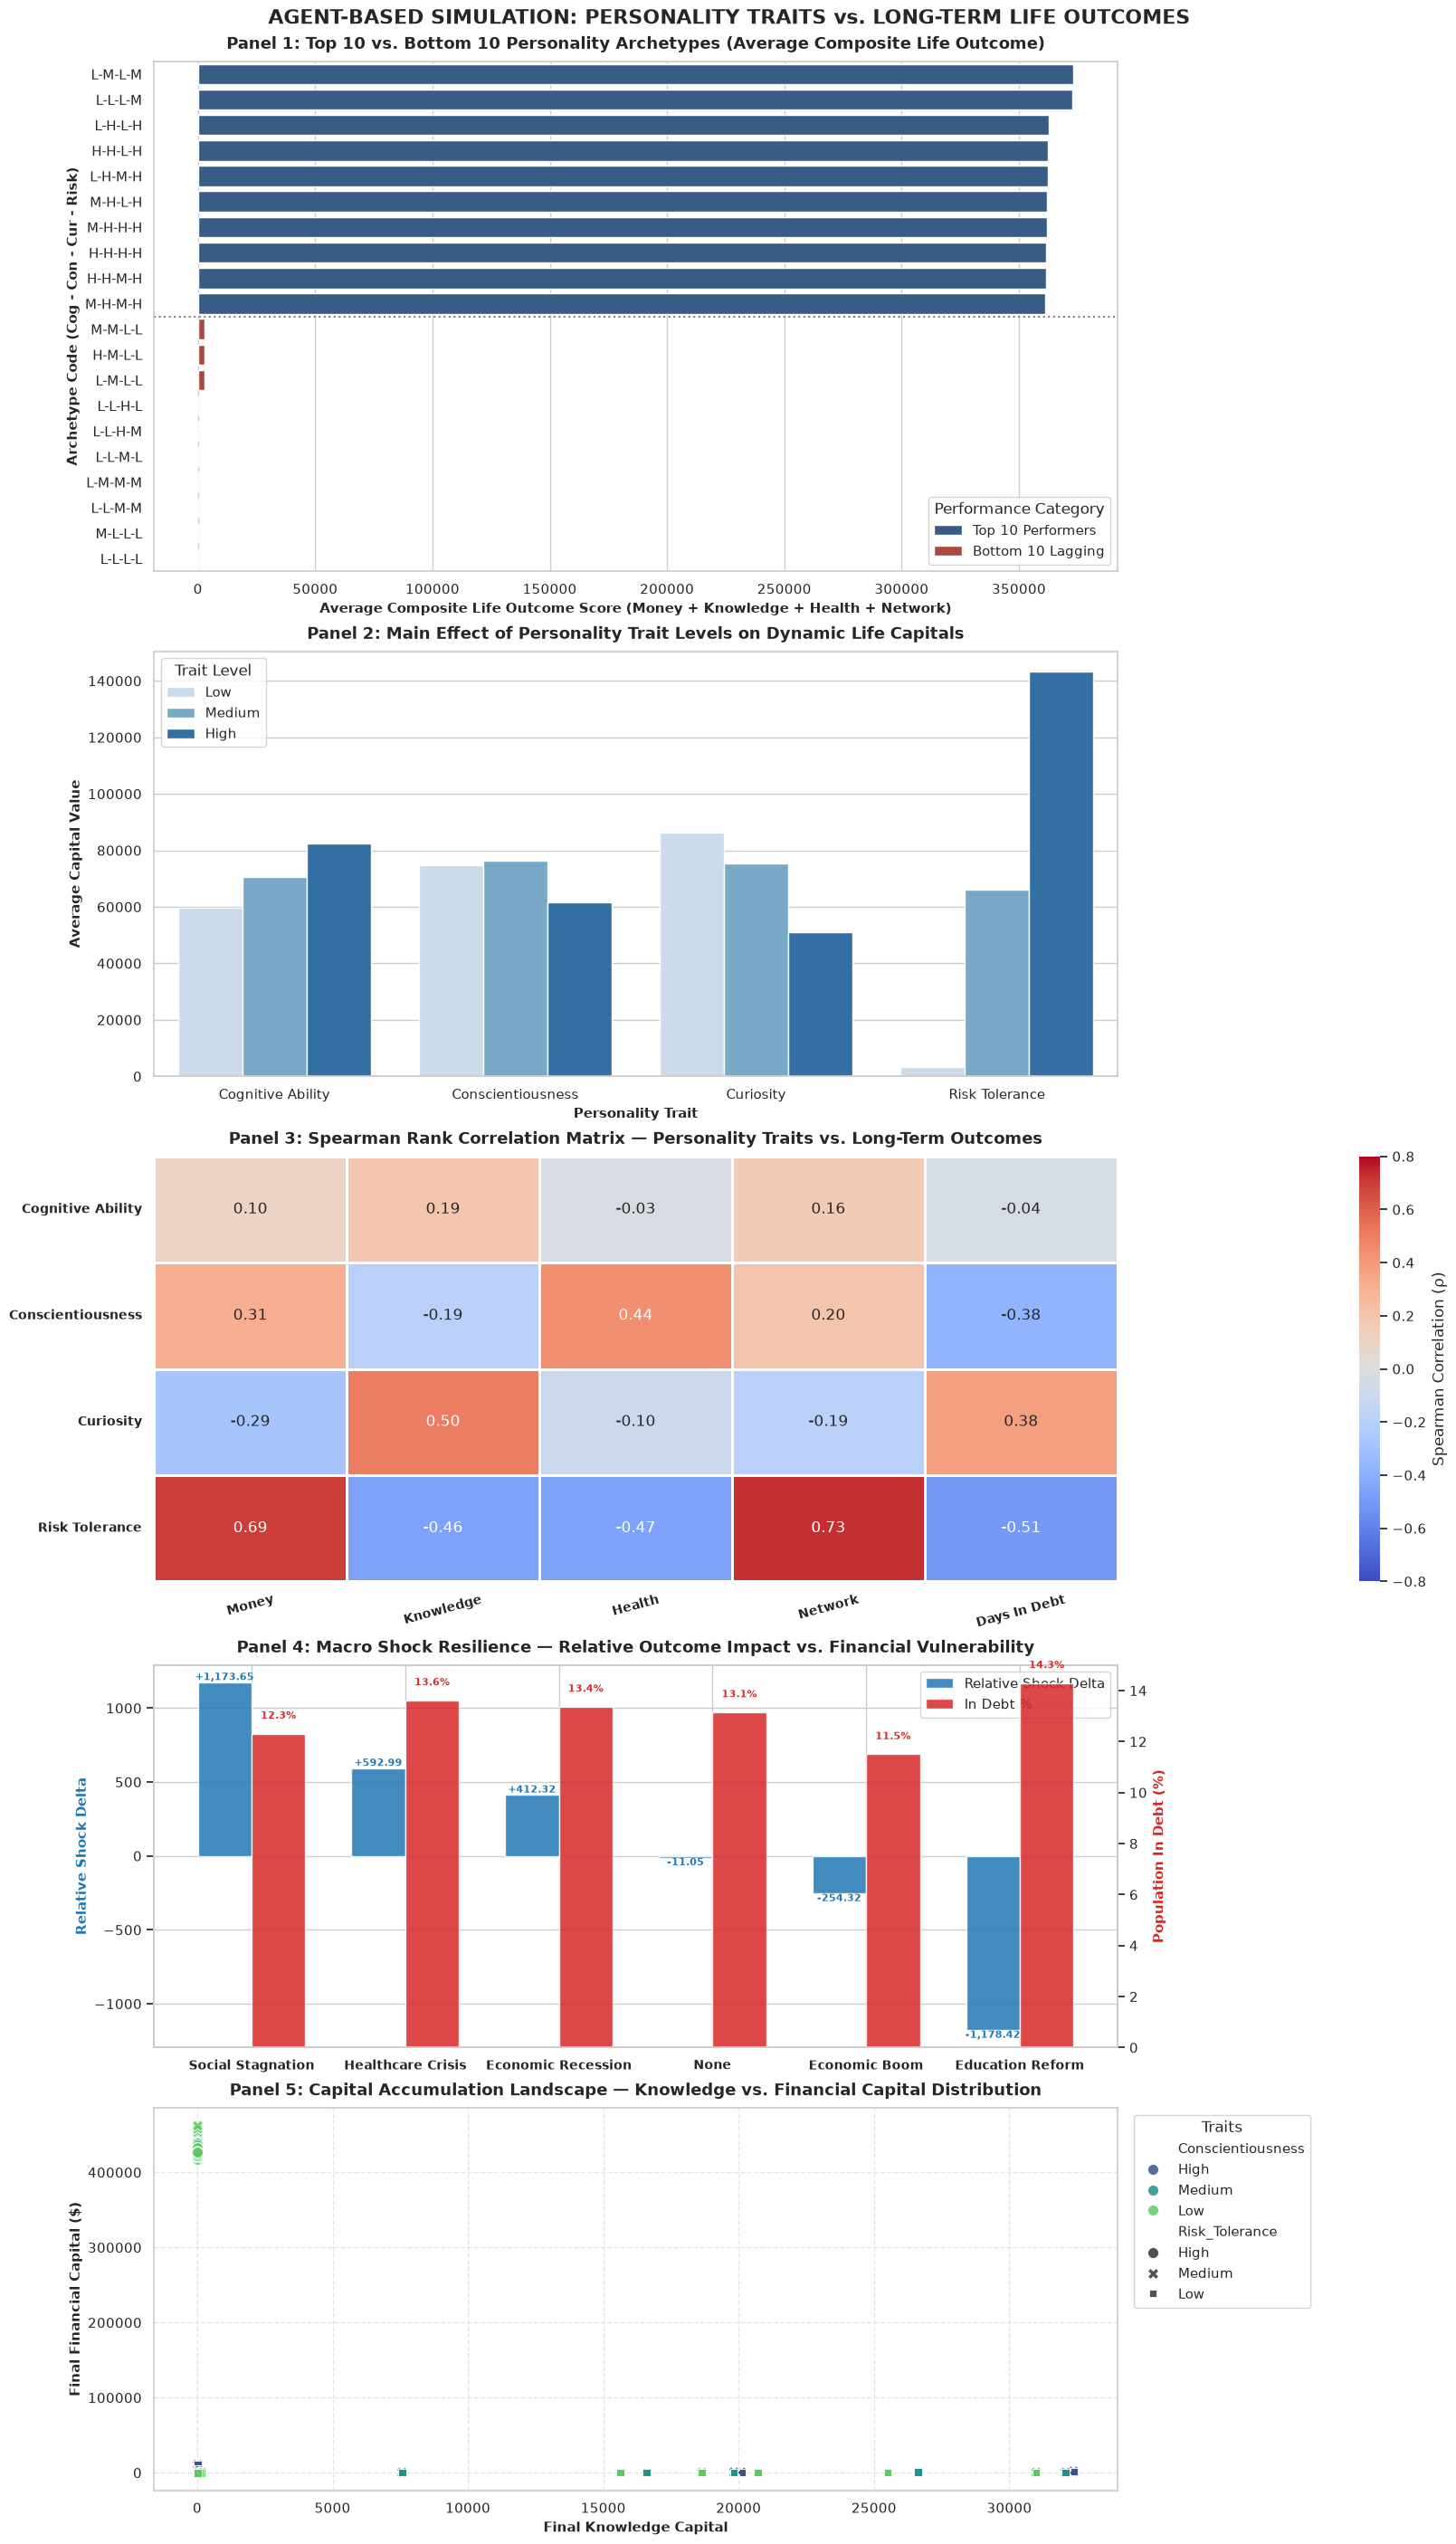

✓ Cell 10 complete: Master dashboard and CSV exports executed successfully!


In [11]:
# ==============================================================================
# CELL 10: Master Visualizations Dashboard & Automatic CSV Export
# (Statistically Corrected & Enhanced Version)
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# 0. Setup Output Directory & Automatic CSV Storage
# ------------------------------------------------------------------------------
output_folder = (
    f"./video/APA_{AGENTS_PER_ARCHETYPE}"
    f"_edu_{BASE_EDUCATION_QUALITY}"
    f"_eco_{BASE_ECONOMIC_GROWTH}"
    f"_heal_{BASE_HEALTHCARE_QUALITY}"
    f"_mob_{BASE_SOCIAL_MOBILITY}"
) if 'AGENTS_PER_ARCHETYPE' in globals() else "./simulation_outputs"

os.makedirs(output_folder, exist_ok=True)

print("💾 Exporting Aggregated Simulation Datasets to CSV...")

# CSV 1: Lifetime Archetype Performance Summary
csv_archetype_path = os.path.join(output_folder, "archetype_performance_summary.csv")
df_archetype_summary.to_csv(csv_archetype_path)
print(f"  ✓ Saved Archetype Summary      -> {csv_archetype_path}")

# CSV 2: Macro Shock Impact Breakdown
csv_shock_path = os.path.join(output_folder, "macro_shock_impact_summary.csv")
df_shock_impact.to_csv(csv_shock_path, index=False)
print(f"  ✓ Saved Shock Impact Summary   -> {csv_shock_path}")

# CSV 3: Final Agent-Level Results
if 'df_results' in globals():
    csv_results_path = os.path.join(output_folder, "final_agent_results.csv")
    df_results.to_csv(csv_results_path, index=False)
    print(f"  ✓ Saved Final Agent Results    -> {csv_results_path}")

# CSV 4: Daily Archetype Time-Series
if 'df_daily_archetype' in globals():
    csv_daily_path = os.path.join(output_folder, "daily_archetype_history.csv")
    df_daily_archetype.to_csv(csv_daily_path, index=False)
    print(f"  ✓ Saved Daily History          -> {csv_daily_path}")

print("✅ All datasets stored successfully!\n")

# ------------------------------------------------------------------------------
# 1. Dashboard Figure & Grid Setup
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(16, 28), dpi=100, layout="constrained")
gs = fig.add_gridspec(5, 1, height_ratios=[1.2, 1.0, 1.0, 0.9, 0.9])

fig.suptitle(
    "AGENT-BASED SIMULATION: PERSONALITY TRAITS vs. LONG-TERM LIFE OUTCOMES",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------------------------
# PANEL 1: Top 10 vs. Bottom 10 Archetypes (Composite Outcome Comparison)
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

# Ensure explicit sorting by lifetime Avg_Composite before slicing
df_sorted_summary = df_archetype_summary.sort_values(by="Avg_Composite", ascending=False)

top_10 = df_sorted_summary.head(10).copy()
bot_10 = df_sorted_summary.tail(10).copy()

top_10["Performance_Group"] = "Top 10 Performers"
bot_10["Performance_Group"] = "Bottom 10 Lagging"

top_bot_df = pd.concat([top_10, bot_10])

sns.barplot(
    data=top_bot_df,
    x="Avg_Composite",
    y="Code",
    hue="Performance_Group",
    palette={"Top 10 Performers": "#2b5c8f", "Bottom 10 Lagging": "#c0392b"},
    ax=ax1
)

ax1.set_title("Panel 1: Top 10 vs. Bottom 10 Personality Archetypes (Average Composite Life Outcome)", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Average Composite Life Outcome Score (Money + Knowledge + Health + Network)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Archetype Code (Cog - Con - Cur - Risk)", fontsize=11, fontweight="bold")
ax1.legend(title="Performance Category", loc="lower right", frameon=True)
ax1.axhline(9.5, color="gray", linestyle=":", linewidth=1.5)

# ------------------------------------------------------------------------------
# PANEL 2: Main Effects of Traits Across All Four Life Capitals
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])

TRAIT_NAMES_LIST = TRAIT_NAMES if 'TRAIT_NAMES' in globals() else ["Cognitive_Ability", "Conscientiousness", "Curiosity", "Risk_Tolerance"]

df_melted_capitals = df_results.melt(
    id_vars=[t for t in TRAIT_NAMES_LIST if t in df_results.columns],
    value_vars=[c for c in ["Final_Money", "Final_Knowledge", "Final_Health", "Final_Network"] if c in df_results.columns],
    var_name="Capital_Type",
    value_name="Capital_Value"
)

df_traits_long = df_melted_capitals.melt(
    id_vars=["Capital_Type", "Capital_Value"],
    value_vars=[t for t in TRAIT_NAMES_LIST if t in df_melted_capitals.columns],
    var_name="Trait_Name",
    value_name="Trait_Level"
)

df_traits_long["Trait_Name"] = df_traits_long["Trait_Name"].str.replace("_", " ")
df_traits_long["Capital_Type"] = df_traits_long["Capital_Type"].str.replace("Final_", "")

sns.barplot(
    data=df_traits_long,
    x="Trait_Name",
    y="Capital_Value",
    hue="Trait_Level",
    hue_order=[lvl for lvl in ["Low", "Medium", "High", "L", "M", "H"] if lvl in df_traits_long["Trait_Level"].unique()],
    palette="Blues",
    errorbar=None,
    ax=ax2
)

ax2.set_title("Panel 2: Main Effect of Personality Trait Levels on Dynamic Life Capitals", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Personality Trait", fontsize=11, fontweight="bold")
ax2.set_ylabel("Average Capital Value", fontsize=11, fontweight="bold")
ax2.legend(title="Trait Level", loc="upper left", frameon=True)

# ------------------------------------------------------------------------------
# PANEL 3: Spearman Rank Correlation Matrix (Traits vs. Outcomes & Debt)
# ------------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[2, 0])

numeric_df = df_results.copy()

# Universal trait mapping dictionary
TRAIT_MAP = {
    "Low": 1, "Medium": 2, "High": 3,
    "L": 1, "M": 2, "H": 3,
    "1": 1, "2": 2, "3": 3
}

# 1. Force mapping of string/categorical traits to ordinal integers
for t in TRAIT_NAMES_LIST:
    if t in numeric_df.columns:
        numeric_df[t] = numeric_df[t].astype(str).map(TRAIT_MAP).fillna(numeric_df[t])
        numeric_df[t] = pd.to_numeric(numeric_df[t], errors="coerce")

# 2. Define target variables
target_outcomes = ["Final_Money", "Final_Knowledge", "Final_Health", "Final_Network", "Days_In_Debt", "Composite_Score"]
existing_traits = [t for t in TRAIT_NAMES_LIST if t in numeric_df.columns]
existing_outcomes = [c for c in target_outcomes if c in numeric_df.columns]

corr_vars = existing_traits + existing_outcomes

# 3. Numeric conversion for safety
for col in corr_vars:
    numeric_df[col] = pd.to_numeric(numeric_df[col], errors="coerce")

# 4. Compute Spearman Rank Correlation (Non-parametric / Ordinal-Safe)
corr_matrix = numeric_df[corr_vars].corr(method="spearman")

# 5. Extract trait rows vs outcome columns for visual output
valid_traits = [t for t in existing_traits if t in corr_matrix.index]
valid_outcomes = [c for c in existing_outcomes if c in corr_matrix.columns]

trait_corr = corr_matrix.loc[valid_traits, valid_outcomes]

sns.heatmap(
    trait_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.8,
    vmax=0.8,
    cbar_kws={"label": "Spearman Correlation (ρ)"},
    linewidths=1.0,
    ax=ax3
)

ax3.set_title("Panel 3: Spearman Rank Correlation Matrix — Personality Traits vs. Long-Term Outcomes", fontsize=13, fontweight="bold", pad=10)
ax3.set_yticklabels([t.replace("_", " ") for t in valid_traits], rotation=0, fontsize=10, fontweight="bold")
ax3.set_xticklabels([c.replace("Final_", "").replace("_", " ") for c in valid_outcomes], rotation=15, fontsize=10, fontweight="bold")

# ------------------------------------------------------------------------------
# PANEL 4: Time-Detrended Macro Shock Resilience Breakdown
# ------------------------------------------------------------------------------
ax4 = fig.add_subplot(gs[3, 0])

color_score = "#1f77b4"
color_debt = "#d62728"

x_labels = df_shock_impact["Active_Shock"].tolist()
x_indices = np.arange(len(x_labels))
bar_width = 0.35

# Plot Relative_Impact_Delta (Time-Detrended) if available, otherwise fallback to Avg_Composite
score_col = "Relative_Impact_Delta" if "Relative_Impact_Delta" in df_shock_impact.columns else "Avg_Composite"
score_label = "Relative Shock Delta" if score_col == "Relative_Impact_Delta" else "Avg Composite Score"

rects1 = ax4.bar(x_indices - bar_width/2, df_shock_impact[score_col], bar_width, label=score_label, color=color_score, alpha=0.85)

ax4_debt = ax4.twinx()
rects2 = ax4_debt.bar(x_indices + bar_width/2, df_shock_impact["In_Debt_Pct"], bar_width, label="In Debt %", color=color_debt, alpha=0.85)

ax4.set_title("Panel 4: Macro Shock Resilience — Relative Outcome Impact vs. Financial Vulnerability", fontsize=13, fontweight="bold", pad=10)
ax4.set_xticks(x_indices)
ax4.set_xticklabels(x_labels, rotation=0, fontsize=10, fontweight="bold")
ax4.set_ylabel(score_label, color=color_score, fontsize=11, fontweight="bold")
ax4_debt.set_ylabel("Population In Debt (%)", color=color_debt, fontsize=11, fontweight="bold")
ax4_debt.grid(False)

for bar in rects1:
    h = bar.get_height()
    va_align = 'bottom' if h >= 0 else 'top'
    ax4.text(bar.get_x() + bar.get_width()/2., h + (0.01 if h >= 0 else -0.05), f"{h:+,.2f}" if score_col == "Relative_Impact_Delta" else f"{h:,.0f}", ha='center', va=va_align, fontsize=8, color=color_score, fontweight='bold')

for bar in rects2:
    h = bar.get_height()
    ax4_debt.text(bar.get_x() + bar.get_width()/2., h + 0.5, f"{h:.1f}%", ha='center', va='bottom', fontsize=8, color=color_debt, fontweight='bold')

lines1, labels1 = ax4.get_legend_handles_labels()
lines2, labels2 = ax4_debt.get_legend_handles_labels()
ax4.legend(lines1 + lines2, labels1 + labels2, loc="upper right", frameon=True)

# ------------------------------------------------------------------------------
# PANEL 5: Capital Trade-Off Scatter — Knowledge vs. Financial Capital
# ------------------------------------------------------------------------------
ax5 = fig.add_subplot(gs[4, 0])

sns.scatterplot(
    data=df_results,
    x="Final_Knowledge",
    y="Final_Money",
    hue="Conscientiousness" if "Conscientiousness" in df_results.columns else None,
    style="Risk_Tolerance" if "Risk_Tolerance" in df_results.columns else None,
    palette="viridis",
    s=75,
    alpha=0.85,
    ax=ax5
)

ax5.set_title("Panel 5: Capital Accumulation Landscape — Knowledge vs. Financial Capital Distribution", fontsize=13, fontweight="bold", pad=10)
ax5.set_xlabel("Final Knowledge Capital", fontsize=11, fontweight="bold")
ax5.set_ylabel("Final Financial Capital ($)", fontsize=11, fontweight="bold")
ax5.legend(title="Traits", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax5.grid(True, linestyle="--", alpha=0.5)

plt.show()

print("✓ Cell 10 complete: Master dashboard and CSV exports executed successfully!")